## Red light violation detection





Installing dependencies

In [3]:
!pip install -q ultralytics opencv-python

### Model loading for  yolo

In [4]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

model = YOLO("yolo11n.pt")
print("Model loaded successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully!


Sample image testing for yolo


0: 640x480 4 persons, 1 bus, 872.9ms
Speed: 20.8ms preprocess, 872.9ms inference, 27.6ms postprocess per image at shape (1, 3, 640, 480)


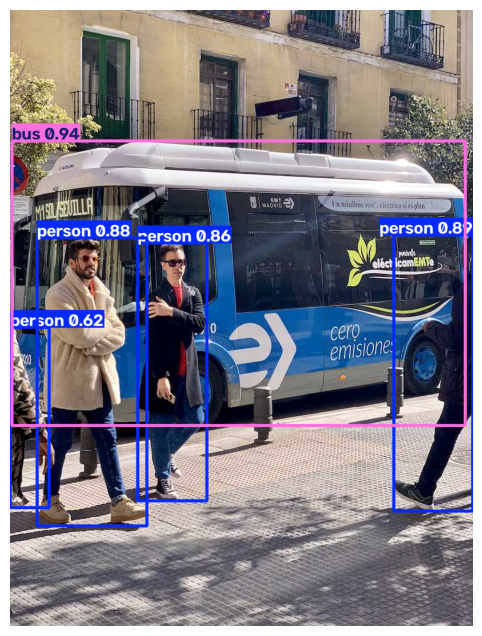

In [5]:
!wget -q https://ultralytics.com/images/bus.jpg -O bus.jpg

image = cv2.imread("bus.jpg")
results = model(image)
annotated_image = results[0].plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.axis("off")
plt.show()


In [6]:

result = results[0]

boxes = result.boxes

for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    print({
        "class": class_name,
        "confidence": round(confidence, 3),
        "bbox": [
            x1,
            y1,
            x2,
            y2
        ]
    })


{'class': 'bus', 'confidence': 0.94, 'bbox': [3.8327178955078125, 229.36427307128906, 796.194580078125, 728.4122924804688]}
{'class': 'person', 'confidence': 0.888, 'bbox': [671.0172119140625, 394.83319091796875, 809.8097534179688, 878.7124633789062]}
{'class': 'person', 'confidence': 0.878, 'bbox': [47.404701232910156, 399.5651550292969, 239.3006591796875, 904.1949462890625]}
{'class': 'person', 'confidence': 0.856, 'bbox': [223.0589599609375, 408.68865966796875, 344.4676513671875, 860.435791015625]}
{'class': 'person', 'confidence': 0.622, 'bbox': [0.021725893020629883, 556.0684204101562, 68.88552856445312, 872.3591918945312]}


### We need to focus on vehicles so we use a filter

In [7]:
VEHICLE_CLASSES = [2, 3, 5, 7]

def detect_vehicles(image):

    results = model(image, verbose=False)
    vehicles = []

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        if class_id not in VEHICLE_CLASSES:
            continue

        x1, y1, x2, y2 = box.xyxy[0].tolist()
        confidence = float(box.conf[0])

        vehicles.append({
            "class": model.names[class_id],
            "confidence": confidence,
            "bbox": (int(x1), int(y1), int(x2), int(y2))
        })

    return vehicles


In [8]:
vehicles = detect_vehicles(image)

for vehicle in vehicles:
    print(vehicle)


{'class': 'bus', 'confidence': 0.9401523470878601, 'bbox': (3, 229, 796, 728)}


### Byte Track

Used to track a vehicle across multiple frames and give it a unique ID.

In [9]:
from google.colab import drive

drive.mount('/content/drive')
folder =  "/content/drive/MyDrive"

Mounted at /content/drive


In [10]:
video_path = os.path.join(folder, "redlightvio.mp4")

cap = cv2.VideoCapture(video_path)

print("Video opened:", cap.isOpened())
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))

Video opened: True
Frames: 2701
FPS: 30.0


In [18]:
model = YOLO("yolo11n.pt")

results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    classes=[2, 3, 5, 7],
    conf=0.25,
    persist=True,
    vid_stride=3,
    stream=True,
    device="cpu",
    verbose=False
)

In [12]:
# from IPython.display import display, clear_output
# from PIL import Image

# for result in results:
#     frame = result.plot()
#     frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

#     clear_output(wait=True)
#     display(Image.fromarray(frame))

### Red light introduction methods



1.   Boolean red light (provided to us externally).
2.   Red light detection via image.

In the project I am using red light as a boolean .

One innovative method could also be that if some vehicles are stopping just behind the zebra crossing then currently the traffic light is red


### The stopping line

The line which if crossed indicates a violation. According to traffic rules it is the zebra crossing.

But for our work we need to draw the line a bit away from the zebra crossing to prevent false positives. As the boxes generated by our model can be slightly larger than the vehicle.

Setting up where the stop line.

In [13]:
LINE_Y = 600
LINE_X1 = 1000
LINE_X2 = 1900

RED_LIGHT = True # will be provided externally

#### Visualising the stop line

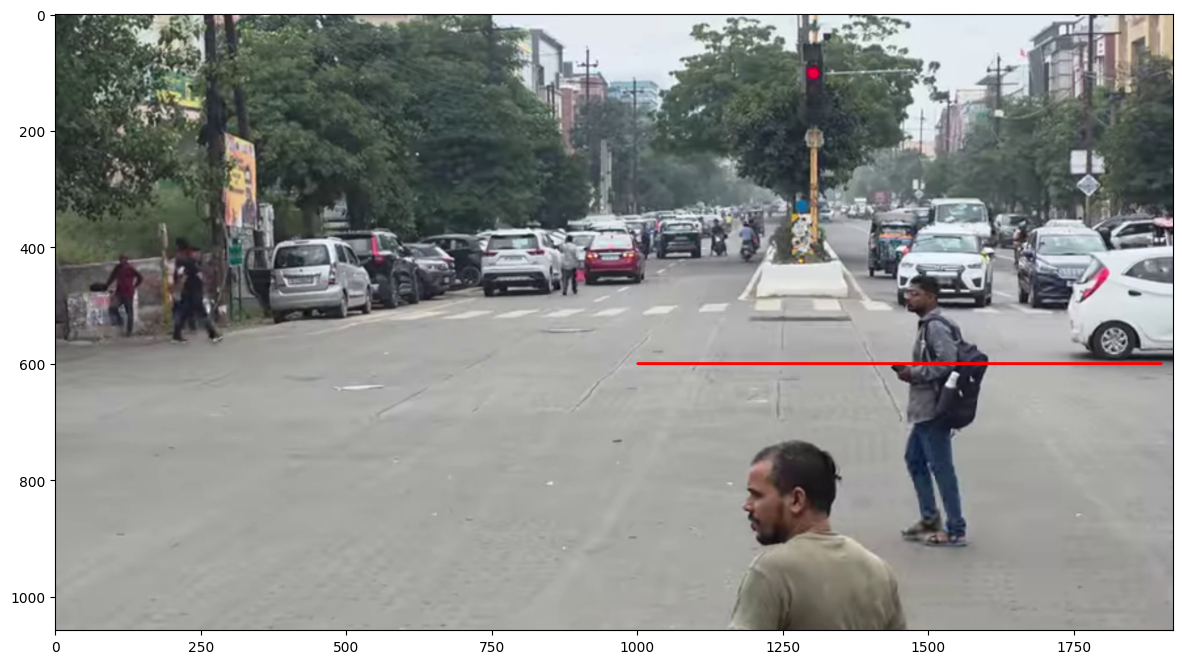

In [14]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

cv2.line(
    frame,
    (LINE_X1, LINE_Y),
    (LINE_X2, LINE_Y),
    (0, 0, 255),
    3
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("on")
plt.show()

In [15]:
previous_positions = {}
violated_vehicles = set()
violations = []




def check_crossing(track_id, x, y, timestamp):

    previous = previous_positions.get(track_id)

    crossed = False

    if previous is not None:

        prev_x, prev_y = previous
        MIN_MOVEMENT = 10
        # Vehicle crosses from above to below the line (This is used to maintain the directional nature)
        if prev_y < LINE_Y <= y and y - prev_y >= MIN_MOVEMENT:
          #Checking that they are within the x-axis
            if LINE_X1 <= x <= LINE_X2:
                crossed = True
                if RED_LIGHT and track_id not in violated_vehicles:
                    violated_vehicles.add(track_id)
                    violations.append({
                        "vehicle_id": track_id,
                        "timestamp": round(timestamp, 2),
                        "position": (x, y),
                        "signal": "RED"
                    })

                    print("VIOLATION:", violations[-1])

    previous_positions[track_id] = (x, y)

    return crossed


In [16]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

print("Video FPS:", fps)

cap.release()

Video FPS: 30.0


In [19]:

model = YOLO("yolo11n.pt")

previous_positions = {}
violated_vehicles = set()
violations = []

results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    classes=[2, 3, 5, 7],
    conf=0.25,
    persist=True,
    stream=True,
    vid_stride=3,
    device="cpu",
    verbose=False
)

for frame_idx, result in enumerate(results):
    #because vidstride = 3
    timestamp = frame_idx * 3 / fps

    if result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    ids = result.boxes.id.cpu().numpy()

    for box, track_id in zip(boxes, ids):

        x1, y1, x2, y2 = box

        # Bottom-center of vehicle
        center_x = int((x1 + x2) / 2)
        bottom_y = int(y2)

        track_id = int(track_id)

        check_crossing(
            track_id,
            center_x,
            bottom_y,
            timestamp
        )

print("Total violations:", len(violations))


VIOLATION: {'vehicle_id': 1132, 'timestamp': 78.7, 'position': (1643, 605), 'signal': 'RED'}
VIOLATION: {'vehicle_id': 1163, 'timestamp': 79.9, 'position': (1298, 608), 'signal': 'RED'}
Total violations: 2


Accuracy in the example video

False positives = 0  
False negatives = 1  
True positives = 2  

The one false negative we get is a bike turning right it probably does not satisfy the downward movement criteria that's why we miss it.


the right turn might not be checked by one line can we use 2 lines?

## How about 2 lines

They will help us check for more particular and precise movement

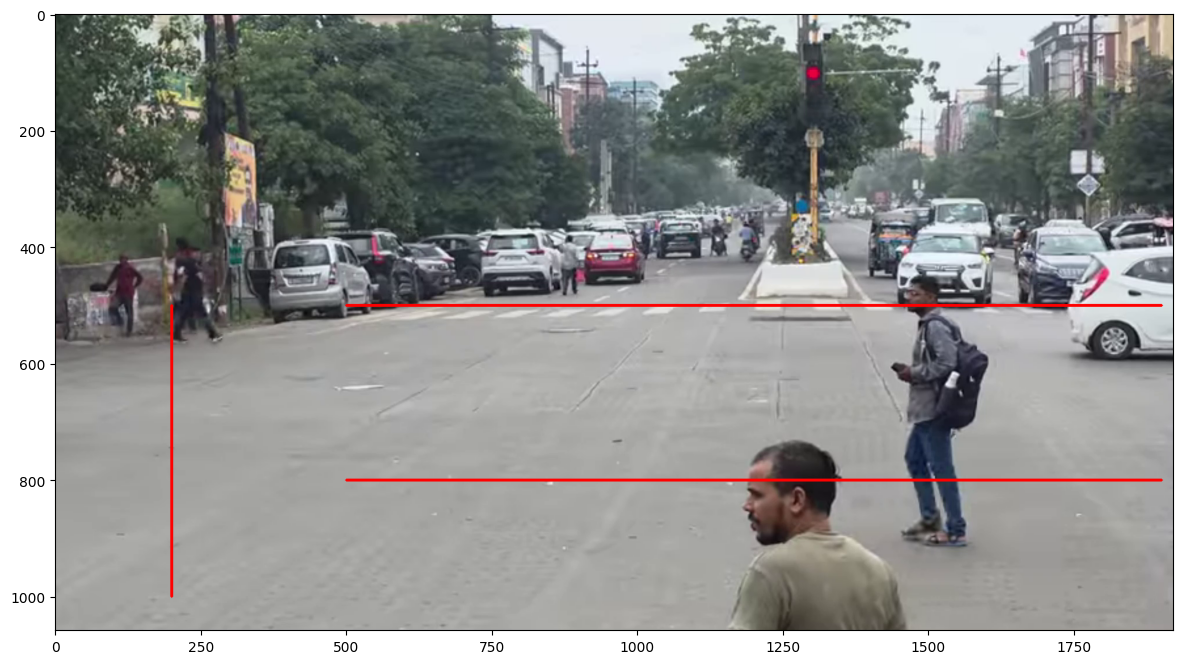

In [24]:
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()
liny1 = 500
liny2 = 800
linx1 = 500
linx2 = 1900


rliny1 = 500
rlinx1 = 200
rliny2 = 1000
rlinx2 = 200
cv2.line(
    frame,
    (linx1, liny1),
    (linx2, liny1),
    (0, 0, 255),
    3
)
cv2.line(
    frame,
    (linx1, liny2),
    (linx2, liny2),
    (0, 0, 255),
    3
)
cv2.line(
    frame,
    (rlinx1, rliny1),
    (rlinx2, rliny2),
    (0, 0, 255),
    3
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("on")
plt.show()

In [ ]:
LINE_A_Y = 500
LINE_B_Y = 700
LINE_C_X = 200

RED_LIGHT = True

In [ ]:
line_A_vehicles = set()
line_B_vehicles = set()
line_C_vehicles = set()
model = YOLO("yolo11n.pt")

previous_positions = {}
def check_crossing(track_id, x, y):

    current = (x, y)
    previous = previous_positions.get(track_id)

    if previous is None:
        previous_positions[track_id] = current
        return

    prev_x, prev_y = previous

    if prev_y < LINE_A_Y <= y:
        line_A_vehicles.add(track_id)

    if prev_y < LINE_B_Y <= y:

        line_B_vehicles.add(track_id)

    if prev_x < LINE_C_X <= x:
        line_C_vehicles.add(track_id)
    previous_positions[track_id] = current

In [ ]:
VID_STRIDE = 3

results = model.track(
    source=video_path,
    tracker="bytetrack.yaml",
    classes=[2, 3, 5, 7],
    conf=0.25,
    persist=True,
    stream=True,
    vid_stride=VID_STRIDE,
    device="cpu",
    verbose=False
)

processed_frame_idx = 0

for result in results:

    if result.boxes is None or result.boxes.id is None:
        processed_frame_idx += 1
        continue

    ids = result.boxes.id.int().cpu().tolist()
    boxes = result.boxes.xyxy.cpu().tolist()

    for track_id, (x1, y1, x2, y2) in zip(ids, boxes):
        x = int((x1 + x2) / 2)
        y = int(y2)

        check_crossing(track_id, x, y)

    processed_frame_idx += 1

print("Video processing complete.")

In [ ]:
if RED_LIGHT:
    violations = sorted(
        line_A_vehicles & (line_B_vehicles | line_C_vehicles)
    )
else:
    violations = []

print("Vehicles crossing Line A:", sorted(line_A_vehicles))
print("Vehicles crossing Line B:", sorted(line_B_vehicles))
print("Vehicles crossing Line C:", sorted(line_C_vehicles))

print("\nTotal vehicles crossing A:", len(line_A_vehicles))
print("Total vehicles crossing B:", len(line_B_vehicles))
print("Total vehicles crossing C:", len(line_C_vehicles))

print("\nVIOLATIONS:", violations)
print("Total violations:", len(violations))

Change the guy turning right is caught this time but another wrong side guys escapes but that is due to it's delayed detection by our yolo model. Due to which it never crosses line A.

### More existing Approaches



1.   Trajectory based approach :-  The vehicles travelling coords are used to get know it's trajectory if it is a right turn, left turn or straight.
2.   Polygon Based Detection Zones :- It's detecting logic works upon dividing the space into polygons and creating a start zone, straight zone and a right turn zone.



